# Stock Prices - Exploratory Data Analysis

This notebook performs comprehensive exploratory data analysis on the stock prices dataset, including:
- Missing values analysis
- Outliers detection and documentation
- Price trend visualizations
- Data quality assessment

## 1. Load Data

In [2]:
import pandas as pd
import plotly.express as px

prices_df = pd.read_csv('../data/stock_prices.csv')

prices_df['Date'] = pd.to_datetime(prices_df['Date'])

In [3]:
print("--- Initial prices_df Info ---")
print(prices_df.info())

--- Initial prices_df Info ---
<class 'pandas.DataFrame'>
RangeIndex: 3644 entries, 0 to 3643
Columns: 544 entries, Date to ZNGA
dtypes: datetime64[us](1), float64(543)
memory usage: 15.1 MB
None


## 2. Missing Values Analysis

In [4]:
missing_counts = prices_df.isnull().sum()
missing_percentages = 100 * prices_df.isnull().sum() / len(prices_df)

missing_df = pd.DataFrame({
    'Missing Count': missing_counts,
    'Percentage': missing_percentages
})

print("Missing Values Summary:")
print(missing_df[missing_df['Missing Count'] > 0].sort_values('Missing Count', ascending=False))

total_missing_pct = 100 * prices_df.isnull().sum().sum() / (prices_df.shape[0] * prices_df.shape[1])
print(f"\nTotal missing data: {total_missing_pct:.2f}%")

Missing Values Summary:
      Missing Count  Percentage
GOOG           3456   94.840834
NWSA           3264   89.571899
ABBV           3137   86.086718
ADT            3086   84.687157
KRFT           3069   84.220637
...             ...         ...
USB             111    3.046103
A               111    3.046103
XRAY            111    3.046103
UNM              34    0.933041
PGR              13    0.356751

[543 rows x 2 columns]

Total missing data: 9.92%


## 3. Outliers Analysis

In [5]:
outlier_rows = []

for col in prices_df.columns[1:]:
    Q1 = prices_df[col].quantile(0.25)
    Q3 = prices_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    mask = (prices_df[col] < lower) | (prices_df[col] > upper)

    outlier_count = (mask).sum()
    outlier_pct = (outlier_count / len(prices_df)) * 100
    
    if mask.any():
        idx = mask.idxmax()
        outlier_rows.append({
            'date': prices_df.loc[idx, prices_df.columns[0]],
            'ticker': col,
            'price': prices_df.loc[idx, col]
        })

outliers = (
    pd.DataFrame(outlier_rows)
      .sort_values("date")
      .reset_index(drop=True)
)

print(outliers)

          date ticker       price
0   2000-12-12    THC  105.333333
1   2000-12-12    RSH   42.277341
2   2000-12-12   BRCM   88.586549
3   2000-12-12   NTAP   80.741692
4   2000-12-12     MU   36.250000
..         ...    ...         ...
297 2014-12-11    HSP   62.080000
298 2014-12-18    ALL   69.790000
299 2014-12-18    IRM   40.270000
300 2014-12-22    AIV   38.320000
301 2014-12-26     NU   55.670000

[302 rows x 3 columns]


## 4. Price Trends Over Time

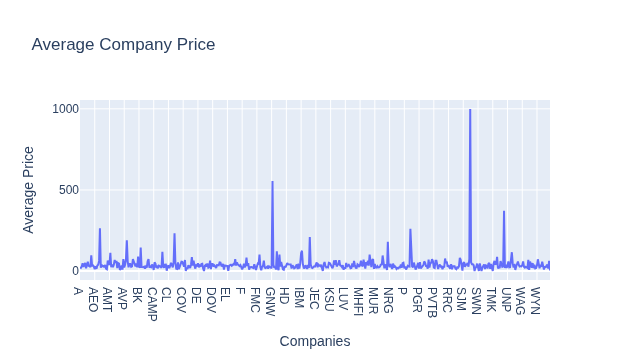

In [6]:
def plot_average_price_over_time(plot=False):
    avg_price_over_time = prices_df.iloc[:, 1:].clip(lower=0.1, upper=1000).mean(skipna=True)
    avg_price_over_time.sort_values(ascending=False)
    avg_price_df = avg_price_over_time.to_frame(name='Average Price')
    avg_price_df.reset_index(inplace=True)
    avg_price_df.rename(columns={'index': 'Companies'}, inplace=True)

    fig = px.line(
        avg_price_df,
        x='Companies',
        y='Average Price',
        title='Average Company Price',
        labels={
            'Companies': 'Companies',
            'Average Price': 'Average Price' 
        }
    )
    if plot:
        plot_path = '../results/plots/average_price_over_time.png'
        fig.write_image(plot_path, width=1000, height=600, scale=2)

    fig.show()

plot_average_price_over_time()

In [7]:
outliers_df = pd.DataFrame(outlier_rows, columns=['date', 'ticker', 'price']).sort_values('price', ascending=False)

combined_df = pd.concat([outliers_df.head(3), outliers_df.tail(2)])

print(combined_df.to_markdown())

combined_df.sort_values('date').to_csv('../results/outliers.txt', sep='\t', index=False)

|     | date                | ticker   |           price |
|----:|:--------------------|:---------|----------------:|
| 242 | 2000-12-15 00:00:00 | SPLS     |    2.34645e+07  |
| 210 | 2013-11-26 00:00:00 | PCLN     | 1177.98         |
| 269 | 2000-12-12 00:00:00 | TYC      | 1082.44         |
|  67 | 2014-04-03 00:00:00 | CSC      |    1.39959e-317 |
| 260 | 2014-03-24 00:00:00 | TMK      |    6.39272e-318 |
